LFPlatoon Final Project Notebook


In [1]:
import requests
import os
import io
import tempfile
import h5py
import math
import get_data
from scipy.signal import decimate
import scipy.io as iomat
# @title
# import core libraries that are used to clean the data and visualize it
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

#import functions for statistical analyses
from scipy import io, signal as sps
from scipy.stats import ttest_ind

#importing pywavelets library to perform CWT and
import pywt

#import models to alter data dimensionality and associate the
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

In [2]:
# @title
!curl -L -o data04.mat "https://api.figshare.com/v2/file/download/43845678"
file = io.loadmat('data04.mat')

lapID = file['lapID']
spikes = file['spikes']
lfps = file['lfps']

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed
100    215 100    215   0      0    341      0                              0
  0      0   0      0   0      0      0      0           00:01              0
100 98.91M 100 98.91M   0      0 26.95M      0   00:03   00:03         36.49M


In [3]:
print(lfps.shape)

(91710, 192)


In [4]:
def get_LFP(lfp_file, n_channels, init_fs, fs=25):
    """
    Decimates LFPs to desired sampling rate

    Input:
    lfp_file = raw lfp data file of type .lfp
    init_fs = inital sampling rate of the data
    fs = desired sampling rate (to decimate to)

    Output:
    X = formatted lfp data
    """
    dec = int(init_fs / fs)
    file_size = os.path.getsize(lfp_file)
    data_size = np.dtype('int16').itemsize
    total_elements = file_size // data_size
    n_samples = total_elements // n_channels

    # Load and decimate the data (takes more memory!)
    # slice_data = np.memmap(lfp_file, dtype='int16', mode='r', shape=(n_samples, n_channels))
    # X = decimate(slice_data[:, :n_keep], dec, axis=0)

    # Process each channel individually and store in the pre-allocated array (takes less memory)
    final_length = math.ceil(n_samples / dec)
    X = np.zeros((final_length, n_keep), dtype=np.float32)
    for channel in range(n_keep):
        # Load the channel data using memmap
        channel_data = np.memmap(lfp_file, dtype='int16', mode='r', shape=(n_samples, n_channels))[:, channel]
        # Decimate the channel data
        X[:, channel] = decimate(channel_data, dec, axis=0)
        print(channel)

    return X


In [5]:
def get_behav(mat_file, fs=25):
    """
    Organizes information about rat behavior into a matrix

    Input:
    mat_file: file containing behavioral data
    fs = sampling frequency

    Output:
    lapID = Data stored in the format listed below

    lapID format:
    Column 0: Trial Number
    Column 1: Maze arm (-1/0/1/2) (-1 = not in maze arm)
    Column 2: Correct (0/1)
    Column 3: other/first approach/port/last departure (0/1/2/3)
    Column 4: x position in mm
    Column 5: y position in mm
    """
    dec = int(1250 / fs)  # decimation factor
    mat = io.loadmat(mat_file, variable_names=['Track'])
    lapID = np.array([np.squeeze(mat['Track']["lapID"][0][0])[::dec]], dtype='float32') - 1
    lapID = np.append(lapID, [np.squeeze(mat['Track']["mazeSect"][0][0])[::dec]], axis=0)
    lapID = np.append(lapID, [np.squeeze(mat['Track']["corrChoice"][0][0])[::dec]], axis=0)
    lapID = np.append(lapID, np.zeros((1, len(lapID[0]))), axis=0)
    lapID = np.append(lapID, decimate(mat['Track']["xMM"][0][0].T, dec), axis=0)
    lapID = np.append(lapID, decimate(mat['Track']["yMM"][0][0].T, dec), axis=0)
    lapID = lapID.T

    # Filter values and construct column 3 using np.isin instead of deprecated np.in1d
    in_arm = np.isin(lapID[:, 1], np.array(range(4, 10)))  # rat is occupying a maze arm
    in_end = np.isin(lapID[:, 1], np.array(range(7, 10)))
    # lapID[np.isin(lapID[:,1], np.array(range(4, 10)), invert = True), 1] = -1
    lapID[in_arm, 1] = (lapID[in_arm, 1] - 1) % 3
    lapID[~in_arm, 1] = -1
    # lapID[lapID[:, 1] == 0, :] = 0

    for i in range(int(np.max(lapID[:, 0]))):
        r = np.logical_and(lapID[:, 0] == i, in_end)  # lapID[:, 3] == 2)
        inds = np.where(np.logical_and(lapID[:, 0] == i, in_arm))[0]
        all_end = np.where(r)[0]
        # if all_end.size > 0: #valid trial where rat goes to end of arm
        if all_end.size > 0:
            lapID[inds[inds < all_end[0]], 3] = 1
            lapID[inds[inds > all_end[-1]], 3] = 3
            # Using a simplified fallback to find longest stretches of True
            # because 'longest_stretch' helper wasn't fully defined
            try:
                lapID[longest_stretch(r), 3] = 2
            except NameError:
                lapID[r, 3] = 2

    # Return structured data
    return lapID

In [6]:
#!curl -O https://raw.githubusercontent.com/beatLaboratory/TIMBRE/main/get_data.py

In [7]:
repository_id = "24757638"  # Behavior_and_spiking_data_for_rats_running_a_3-arm_maze"
url = f"https://api.figshare.com/v2/articles/{repository_id}"

# Make the API request
response = requests.get(url)
files = response.json()['files']
n_channels = [385, 385, 256, 256]

# Loop through a set range
i=3
behav_file_pattern = f"rec0{i + 1}_BehavElectrDataLFP.mat"
lfp_file_pattern = f"rec0{i + 1}.lfp"

# Find the matching files
behav_file = next((file for file in files if file['name'] == behav_file_pattern), None)
lfp_file = next((file for file in files if file['name'] == lfp_file_pattern), None)

# Initialize combined data dictionary
full_data = {}

if behav_file and lfp_file:
    print(f"Downloading files: {behav_file['name']} and {lfp_file['name']}")

    behav_response = requests.get(behav_file['download_url'])
    behav_filename = f"rec0{i + 1}_BehavElectrDataLFP.mat"
    with open(behav_filename, 'wb') as f:
        f.write(behav_response.content)
    print(f"Downloaded {behav_filename}")

    #full_data['behav'] = iomat.loadmat(behav_filename)
    full_data['lapID'] = get_behav(behav_filename)

else:
    print("One or both files not found in the repository." )
'''
# Download LFP file
lfp_response = requests.get(lfp_file['download_url'])
lfp_filename = f"rec0{i + 1}.lfp"
with open(lfp_filename, 'wb') as f:
  f.write(lfp_response.content)
print(f"Downloaded {lfp_filename}")

full_data['lfps'] = get_data.get_LFP(lfp_filename, n_channels[i], 1250)
'''
iomat.savemat(f"beh0{i + 1}.mat", full_data)


Downloaded rec04_BehavElectrDataLFP.mat


In [8]:
file2 = io.loadmat('rec04_lfps.mat')

In [9]:
print(file2['lapID'].shape)

(91710, 6)


In [10]:
# Once we locate the correct field (e.g., 'Laps' or 'lapID'), we can extract it.
# MATLAB structs typically require indexing like [0, 0] to access fields in Python:
# try:
#     laps = file2['behav']['Laps'][0, 0]
#     print(laps)
# except Exception as e:
#     print("Error:", e)

In [11]:
# for pca
def change_of_basis(X, W):
  """
  Projects data onto a new basis.

  Args:
    X (numpy array of floats) : Data matrix each column corresponding to a
                                different random variable
    W (numpy array of floats) : new orthonormal basis columns correspond to
                                basis vectors

  Returns:
    (numpy array of floats)   : Data matrix expressed in new basis
  """

  Y = np.matmul(X, W)

  return Y

# for pca
def get_sample_cov_matrix(X):
  """
  Returns the sample covariance matrix of data X.

  Args:
    X (numpy array of floats) : Data matrix each column corresponds to a
                                different random variable

  Returns:
    (numpy array of floats)   : Covariance matrix
"""

  X = X - np.mean(X, 0)
  cov_matrix = 1 / X.shape[0] * np.matmul(X.T, X)
  return cov_matrix

# for pca
def sort_evals_descending(evals, evectors):
  """
  Sorts eigenvalues and eigenvectors in decreasing order. Also aligns first two
  eigenvectors to be in first two quadrants (if 2D).

  Args:
    evals (numpy array of floats)    :   Vector of eigenvalues
    evectors (numpy array of floats) :   Corresponding matrix of eigenvectors
                                         each column corresponds to a different
                                         eigenvalue

  Returns:
    (numpy array of floats)          : Vector of eigenvalues after sorting
    (numpy array of floats)          : Matrix of eigenvectors after sorting
  """

  index = np.flip(np.argsort(evals))
  evals = evals[index]
  evectors = evectors[:, index]
  if evals.shape[0] == 2:
    if np.arccos(np.matmul(evectors[:, 0],
                           1 / np.sqrt(2) * np.array([1, 1]))) > np.pi / 2:
      evectors[:, 0] = -evectors[:, 0]
    if np.arccos(np.matmul(evectors[:, 1],
                           1 / np.sqrt(2)*np.array([-1, 1]))) > np.pi / 2:
      evectors[:, 1] = -evectors[:, 1]

  return evals, evectors

# pca!
def pca(X):
  """
  Performs PCA on multivariate data. Eigenvalues are sorted in decreasing order

  Args:
     X (numpy array of floats) :   Data matrix each column corresponds to a
                                   different random variable

  Returns:
    (numpy array of floats)    : Data projected onto the new basis
    (numpy array of floats)    : Corresponding matrix of eigenvectors
    (numpy array of floats)    : Vector of eigenvalues
  """

  X = X - np.mean(X, 0)
  cov_matrix = get_sample_cov_matrix(X)
  evals, evectors = np.linalg.eigh(cov_matrix)
  evals, evectors = sort_evals_descending(evals, evectors)
  score = change_of_basis(X, evectors)

  return score, evectors, evals

# for pca and variance
def get_variance_explained(evals):
  """
  Calculates variance explained from the eigenvalues.

  Args:
    evals (numpy array of floats) : Vector of eigenvalues

  Returns:
    (numpy array of floats)       : Vector of variance explained
  """

  # Cumulatively sum the eigenvalues
  csum = np.cumsum(evals)

  # Normalize by the sum of eigenvalues
  variance_explained = csum / np.sum(evals)

  return variance_explained

# to visualize variance explained
def plot_variance_explained(variance_explained):
  """
  Plots eigenvalues.

  Args:
    variance_explained (numpy array of floats) : Vector of variance explained
                                                 for each PC

  Returns:
    Nothing.
  """

  plt.figure()
  plt.plot(np.arange(1, len(variance_explained) + 1), variance_explained,
           '--k')
  plt.xlabel('Number of components')
  plt.ylabel('Variance explained')
# Add scale and grid
  plt.xlim(1,15)
  plt.ylim(0, 1)
  plt.show()

16 of 66 transitions kept


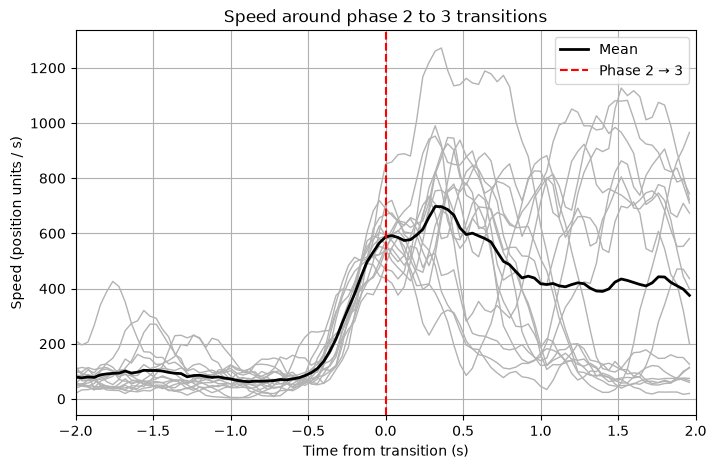

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

# -----------------------------
# Speed calculation
# -----------------------------
fs = 25
dt = 1 / fs

x = lapID[:, 4]
y = lapID[:, 5]

vx = np.diff(x) / dt
vy = np.diff(y) / dt
speed = np.hypot(vx, vy)

# 5-sample moving average (like smoothdata(..., 'movmean', 5))
speed_smooth = uniform_filter1d(speed, size=5, mode="nearest")

t = np.arange(len(speed)) / fs
phase = lapID[:-1, 3]          # same length as speed

# -----------------------------
# Find 2 -> 3 transitions with 2 s of each phase
# -----------------------------
pre = int(2 * fs)              # samples of phase 2 before the transition
post = int(2 * fs)             # samples of phase 3 after the transition

# k where phase[k] == 2 and phase[k+1] == 3
trans_idx = np.where((phase[:-1] == 2) & (phase[1:] == 3))[0]

segments = []
kept_idx = []

for k in trans_idx:
    # skip if the window runs off either end of the recording
    if k - pre + 1 < 0 or k + post >= len(phase):
        continue

    before = phase[k - pre + 1 : k + 1]     # last 2 s of phase 2
    after = phase[k + 1 : k + post + 1]     # first 2 s of phase 3

    if np.all(before == 2) and np.all(after == 3):
        segments.append(speed_smooth[k - pre + 1 : k + post + 1])
        kept_idx.append(k)

print(f"{len(kept_idx)} of {len(trans_idx)} transitions kept")

# -----------------------------
# Plot
# -----------------------------
if len(segments) == 0:
    print("No transitions met the criteria. Try shortening pre/post.")
else:
    segments = np.array(segments).T                  # (pre+post, n_transitions)
    tw = np.arange(-pre, post) / fs                  # 0 = first sample of phase 3

    plt.figure(figsize=(8, 5))
    plt.plot(tw, segments, color="0.7", linewidth=1)                   # individual transitions
    plt.plot(tw, segments.mean(axis=1), "k", linewidth=2, label="Mean")  # average
    plt.axvline(0, color="r", linestyle="--", label="Phase 2 → 3")
    plt.grid(True)
    plt.title("Speed around phase 2 to 3 transitions")
    plt.xlabel("Time from transition (s)")
    plt.ylabel("Speed (position units / s)")
    plt.xlim(-2, 2)
    plt.legend()
    plt.show()